## Activity 3: Statistical Computing Lab

### Warm-up

In [21]:
import numpy as np

# Handout §4.1.2: z-scores for 10 values
v = np.array([103, 108, 112, 118, 238, 135, 109, 156, 142, 158])

z_sample = (v - v.mean()) / v.std(ddof=1)
z_pop = (v - v.mean()) / v.std()

# Handout Example 4.3: office area vs sales
area = np.array([13, 13, 17, 17, 12, 10, 16, 11, 14, 11])
sales = np.array([375, 650, 525, 500, 390, 320, 275, 205, 300, 425])

r = np.corrcoef(area, sales)[0, 1]

# Introduce the typo
area_typo = area.copy()
area_typo[1] = 130

r_typo = np.corrcoef(area_typo, sales)[0, 1]

# Display the required results
print("z for 238 (ddof=1):", z_sample[4])
print("z for 238 (ddof=0):", z_pop[4])
print("r (Example 4.3):", r)
print("r with the typo:", r_typo)


z for 238 (ddof=1): 2.4692100263587404
z for 238 (ddof=0): 2.60277590153934
r (Example 4.3): 0.33725732187695684
r with the typo: 0.6934933235824292


| Check | Expected | Your result | What it teaches |
|---|---:|---:|---|
| z for 238 (ddof = 1) | 2.47 | 2.47 | Matches the handout, which uses the sample SD. |
| z for 238 (ddof = 0) | 2.60 | 2.60 | Always state which SD you used. |
| r (Example 4.3) | 0.291 | 0.337 | Weak positive relationship. |
| r with the typo | 0.690 | 0.693 | One bad value can make a weak link look strong. |

### Setup and Data Preparation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
df = pd.read_csv("../data/interim/seattle_building_energy_api.csv")

print("Dataset successfully loaded!")
print("Shape:", df.shape)

df.head()

Dataset successfully loaded!
Shape: (38309, 50)


,osebuildingid,datayear,buildingname,buildingtype,taxparcelidentificationnumber,address,city,state,zipcode,latitude,longitude,neighborhood,councildistrictcode,yearbuilt,numberoffloors,numberofbuildings,propertygfatotal,propertygfabuildings,propertygfaparking,selfreportgfatotal,selfreportgfabuildings,selfreportparking,epapropertytype,largestpropertyusetype,largestpropertyusetypegfa,secondlargestpropertyusetype,thirdlargestpropertyusetype,electricity_kwh,naturalgas_therms,compliancestatus,electricity_kbtu,naturalgas_kbtu,demolished,:id,:version,:created_at,:updated_at,energystarscore,siteeuiwn_kbtu_sf,siteeui_kbtu_sf,siteenergyuse_kbtu,siteenergyusewn_kbtu,sourceeuiwn_kbtu_sf,sourceeui_kbtu_sf,secondlargestpropertyuse,complianceissue,totalghgemissions,ghgemissionsintensity,steamuse_kbtu,thirdlargestpropertyusetypegfa
0,1,2025,Mayflower Park Hotel,NonResidential,659000030,405 OLIVE WAY,SEATTLE,WA,98101,47.612199,-122.337991,DOWNTOWN,7,1927,12,1,88434,88434,0,115387,115387,0,Hotel,Hotel,115387.0,NaN,NaN,1021340.0,16927.4,Not Compliant,3484810.7,1692740.0,False,row-kn35~mcxx_c7nw,rv-y88d_9273-hvnq,2026-08-28T22:57:57.705Z,2026-08-28T22:57:57.705Z,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2025,Paramount Hotel,NonResidential,659000220,724 PINE ST,SEATTLE,WA,98101,47.613073,-122.333607,EAST,7,1996,11,1,103566,88502,15064,103566,88502,15064,Hotel,Hotel,88502.0,Parking,NaN,775602.0,34847.0,Compliant,2646356.0,3484730.0,False,row-3ch2_z5xm-6j5e,rv-2j6w-9p7c~7aum,2026-08-28T22:57:57.705Z,2026-08-28T22:57:57.705Z,87.0,69.0,69.3,6131086.0,6103114.0,124.2,125.1,15064.0,No Issue,199.75,2.26,NaN,NaN
2,3,2025,Westin Hotel (Parent Building),NonResidential,659000475,1900 5TH AVE,SEATTLE,WA,98101,47.613672,-122.338221,LAKE UNION,7,1969,41,3,956110,759392,196718,947059,827566,119493,Hotel,Hotel,827566.0,Parking,Swimming Pool,11693500.0,51470.0,Compliant,39898222.0,5147040.0,False,row-feuc_8yjs-mvcp,rv-aa2s.ezdc-h2ka,2026-08-28T22:57:57.705Z,2026-08-28T22:57:57.705Z,63.0,89.9,89.9,74382200.0,74382200.0,184.1,184.1,117783.0,No Issue,2880.50,3.48,29336926.0,NaN
3,5,2025,Hotel Max,NonResidential,659000640,620 STEWART ST,SEATTLE,WA,98101,47.614121,-122.336637,LAKE UNION,7,1926,10,1,61320,61320,0,61320,61320,0,Hotel,Hotel,61320.0,NaN,NaN,772199.0,11410.0,Compliant,2634742.0,1141040.0,False,row-fiv9~6nbc~ta76,rv-k5pr~nzwu_wb87,2026-08-28T22:57:57.705Z,2026-08-28T22:57:57.705Z,54.0,83.2,83.6,5125570.0,5099552.0,165.1,166.3,NaN,No Issue,184.94,3.02,1349793.0,NaN
4,8,2025,Warwick Seattle Hotel,NonResidential,659000970,401 LENORA ST,SEATTLE,WA,98121,47.613950,-122.340871,LAKE UNION,7,1980,18,1,175580,113580,62000,203942,123445,80497,Hotel,Hotel,123445.0,Parking,Swimming Pool,1394922.0,58654.0,Compliant,4759474.0,5865420.0,False,row-fv64.8vqh-ee8t,rv-jvd4~x7uq_9k34,2026-08-28T22:57:57.705Z,2026-08-28T22:57:57.705Z,90.0,85.7,86.1,10624897.0,10577956.0,156.8,157.8,68009.0,No Issue,338.20,2.74,NaN,NaN


In [3]:
# Display dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Inspect data types and non-null counts
print("\nDataset Information:")
df.info()

Rows: 38309
Columns: 50

Column Names:
['osebuildingid', 'datayear', 'buildingname', 'buildingtype', 'taxparcelidentificationnumber', 'address', 'city', 'state', 'zipcode', 'latitude', 'longitude', 'neighborhood', 'councildistrictcode', 'yearbuilt', 'numberoffloors', 'numberofbuildings', 'propertygfatotal', 'propertygfabuildings', 'propertygfaparking', 'selfreportgfatotal', 'selfreportgfabuildings', 'selfreportparking', 'epapropertytype', 'largestpropertyusetype', 'largestpropertyusetypegfa', 'secondlargestpropertyusetype', 'thirdlargestpropertyusetype', 'electricity_kwh', 'naturalgas_therms', 'compliancestatus', 'electricity_kbtu', 'naturalgas_kbtu', 'demolished', ':id', ':version', ':created_at', ':updated_at', 'energystarscore', 'siteeuiwn_kbtu_sf', 'siteeui_kbtu_sf', 'siteenergyuse_kbtu', 'siteenergyusewn_kbtu', 'sourceeuiwn_kbtu_sf', 'sourceeui_kbtu_sf', 'secondlargestpropertyuse', 'complianceissue', 'totalghgemissions', 'ghgemissionsintensity', 'steamuse_kbtu', 'thirdlargestprope


The variables selected for this activity are based on their
relevance to building energy performance.

| Variable | Description | Analysis |
|---|---|---|
| siteeui_kbtu_sf | Site Energy Use Intensity | Parts A and B |
| propertygfatotal | Total Property Gross Floor Area | Part C |
| totalghgemissions | Total Greenhouse Gas Emissions | Supporting variable |


In [4]:

# Handle Missing Values

# Check missing values in selected variables
selected_columns = [
    "siteeui_kbtu_sf",
    "propertygfatotal",
    "totalghgemissions"
]

missing_summary = pd.DataFrame({
    "Missing Count": df[selected_columns].isna().sum(),
    "Missing Percentage": (
        df[selected_columns].isna().mean() * 100
    ).round(2)
})

missing_summary


,Missing Count,Missing Percentage
siteeui_kbtu_sf,1562,4.08
propertygfatotal,0,0.00
totalghgemissions,1240,3.24


In [5]:
# Prepare data for statistical analysis

# Part A and B: Site EUI
site_eui = df["siteeui_kbtu_sf"].dropna()

# Part C: Site EUI and Property Gross Floor Area
relationship_data = df[
    ["siteeui_kbtu_sf", "propertygfatotal"]
].dropna()

# Display valid observations
print("Valid Site EUI observations:", len(site_eui))

print(
    "Valid observations for Part C:",
    len(relationship_data)
)

Valid Site EUI observations: 36747
Valid observations for Part C: 36747


### Part A – Describe the Data


#### Define the Numerical Variable

Site Energy Use Intensity (Site EUI) measures the energy
consumed by a building per unit of floor area.

The variable used in this analysis is `siteeui_kbtu_sf`,
measured in kBtu/ft².

Each observation represents one building record in the
Seattle Building Energy dataset.


#### Calculate Summary Statistics

In [6]:
stats = {
    "Valid n": site_eui.count(),
    "Mean": site_eui.mean(),
    "Median": site_eui.median(),
    "SD": site_eui.std(),
    "Min": site_eui.min(),
    "Q1": site_eui.quantile(0.25),
    "Q3": site_eui.quantile(0.75),
    "Max": site_eui.max(),
    "IQR": site_eui.quantile(0.75) - site_eui.quantile(0.25),
    "CV (%)": (site_eui.std() / site_eui.mean()) * 100,
    "Skewness": site_eui.skew()
}

summary = pd.DataFrame(
    stats.items(),
    columns=["Statistic", "Value"]
)

summary["Value"] = summary["Value"].round(2)

summary


,Statistic,Value
0,Valid n,36747.00
1,Mean,57.19
2,Median,36.60
3,SD,377.35
4,Min,0.10
5,Q1,27.30
6,Q3,56.40
7,Max,44197.90
8,IQR,29.10
9,CV (%),659.82


#### Visualize the Distribution

##### Histogram

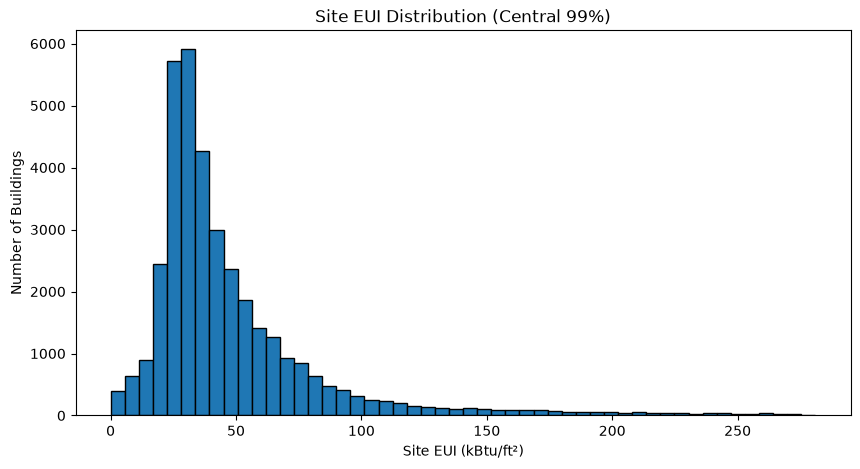

99th percentile: 281.05


In [9]:
upper_limit = site_eui.quantile(0.99)

plt.figure(figsize=(10, 5))

plt.hist(
    site_eui[site_eui <= upper_limit],
    bins=50,
    edgecolor="black"
)

plt.title("Site EUI Distribution (Central 99%)")
plt.xlabel("Site EUI (kBtu/ft²)")
plt.ylabel("Number of Buildings")

plt.show()

print("99th percentile:", round(upper_limit, 2))


##### Box Plot

C:\Users\HP\AppData\Local\Temp\ipykernel_10176\60693225.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(site_eui, vert=False)


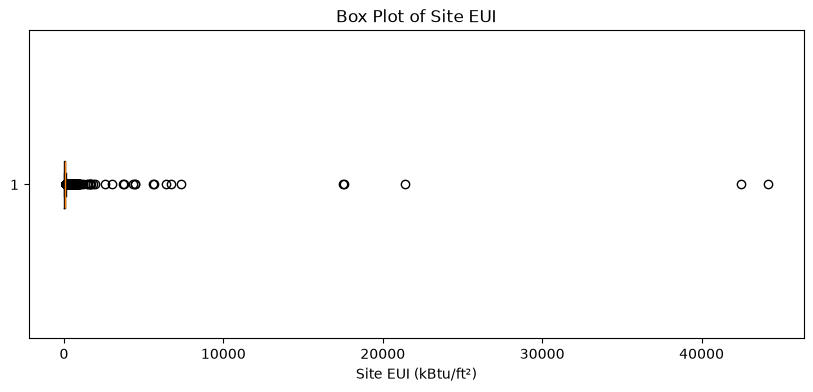

In [8]:
plt.figure(figsize=(10, 4))

plt.boxplot(site_eui, vert=False)

plt.title("Box Plot of Site EUI")
plt.xlabel("Site EUI (kBtu/ft²)")

plt.show()


##### Describe Center, Spread, Skewness, and Possible Outliers

The Site EUI data is **right-skewed**, meaning most buildings have lower Site EUI values, while a few buildings have very high values. The mean (57.19) is higher than the median (36.60), showing that these high values pull the average upward.

The middle 50% of the data is between 27.30 and 56.40 kBtu/ft², with an IQR of 29.10. This means most buildings have Site EUI values within this range. However, the standard deviation of 377.35 is very high because the data contains some extremely large values.

The box plot shows many points beyond the upper whisker, indicating possible outliers. The highest Site EUI is 44,197.90 kBtu/ft², which is much higher than most observations. The central 99% histogram provides a clearer view of the main distribution, showing that most buildings have Site EUI values concentrated at the lower end, with a long tail toward higher values.

These unusual values will be investigated in Part B to determine whether they are possible data errors or legitimate observations.

### Part B – Investigate Unusual Observations

#### Identify Potential Outliers Using IQR

The Interquartile Range (IQR) method helps identify values that are unusually high or low compared with the rest of the data.

We calculate the lower and upper boundaries using these formulas:

Lower boundary = Q1 − 1.5 × IQR

Upper boundary = Q3 + 1.5 × IQR

Values below the lower boundary or above the upper boundary are considered potential outliers. These values will be investigated further, but they will not be removed automatically.

In [10]:

# Calculate the IQR boundaries

Q1 = site_eui.quantile(0.25)
Q3 = site_eui.quantile(0.75)
IQR = Q3 - Q1

lower_boundary = Q1 - 1.5 * IQR
upper_boundary = Q3 + 1.5 * IQR

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Boundary:", round(lower_boundary, 2))
print("Upper Boundary:", round(upper_boundary, 2))


Q1: 27.3
Q3: 56.4
IQR: 29.1
Lower Boundary: -16.35
Upper Boundary: 100.05


In [11]:
# Identify potential outliers

lower_outliers = site_eui[site_eui < lower_boundary]
upper_outliers = site_eui[site_eui > upper_boundary]

print("Lower outliers:", len(lower_outliers))
print("Upper outliers:", len(upper_outliers))
print("Total potential outliers:", 
      len(lower_outliers) + len(upper_outliers))


Lower outliers: 0
Upper outliers: 2980
Total potential outliers: 2980


#### Initial Findings: Potential Outliers

Your IQR results show:

| Measure | Result |
| :--- | :--- |
| Lower boundary | -16.35 |
| Upper boundary | 100.05 |
| Lower outliers | 0 |
| Upper outliers | 2,980 |
| Total potential outliers | 2,980 |

##### Interpretation

There are **2,980 observations** with Site EUI above **100.05 kBtu/ft²**. These are considered potential outliers based on the IQR method.

> **Note:** Potential outliers are not automatically errors. Some buildings may genuinely consume much more energy than others because of their size, activities, or energy requirements.

In [12]:
# Display the 10 highest Site EUI observations

extreme_buildings = df.nlargest(10, "siteeui_kbtu_sf")[
    ["osebuildingid",
     "buildingname",
     "datayear",
     "buildingtype",
     "propertygfatotal",
     "siteeui_kbtu_sf",
     "siteenergyuse_kbtu",
     "totalghgemissions"]
]

extreme_buildings


,osebuildingid,buildingname,datayear,buildingtype,propertygfatotal,siteeui_kbtu_sf,siteenergyuse_kbtu,totalghgemissions
9229,24009,SEA-MAR COMMUNITY CARE CENTER (NURSING HOME),2023,Multifamily LR (1-4),49770,44197.898440,2.394202e+09,126805.10
17927,50239,AMLI Waterfront Apartments,2021,Multifamily HR (10+),200152,42480.199220,6.839772e+09,553724.20
3171,50239,Amli Waterfront Apartments,2025,Multifamily HR (10+),200152,21375.400000,3.689480e+09,20.41
18725,755,MEDICAL DENTAL BUILDING,2020,NonResidential,363934,17549.599610,5.880243e+09,475355.30
22255,755,MEDICAL DENTAL BUILDING,2019,NonResidential,363934,17488.500000,5.859773e+09,473565.50
8954,23120,"WASTE MANAGEMENT MAINTENANCE SHED, BLDG A",2023,NonResidential,26232,7349.600098,1.927944e+08,10188.00
21363,49967,UW - UNIVERSITY OF WASHINGTON SEATTLE CAMPUS (...,2020,University,15216474,6702.899902,1.020000e+11,51045.60
13189,25042,Recovery Place Seattle ALAN FRIEDMAN BUILDING,2022,NonResidential,33332,6389.500000,2.129742e+08,11250.50
5241,23120,"WASTE MANAGEMENT MAINTENANCE SHED, BLDG A",2024,NonResidential,26232,5666.399902,1.486411e+08,7849.50
1560,23120,"Waste Management Maintenance Shed, Bldg A",2025,NonResidential,26232,5588.200000,1.465893e+08,NaN


#### Investigate the Extreme Observations

In [13]:
# Calculate an estimated Site EUI from energy use and floor area

extreme_buildings = extreme_buildings.copy()

extreme_buildings["calculated_eui"] = (
    extreme_buildings["siteenergyuse_kbtu"] /
    extreme_buildings["propertygfatotal"]
)

extreme_buildings["eui_difference"] = (
    extreme_buildings["siteeui_kbtu_sf"] -
    extreme_buildings["calculated_eui"]
)

extreme_buildings[
    ["buildingname",
     "datayear",
     "siteeui_kbtu_sf",
     "calculated_eui",
     "eui_difference"]
].round(2)


,buildingname,datayear,siteeui_kbtu_sf,calculated_eui,eui_difference
9229,SEA-MAR COMMUNITY CARE CENTER (NURSING HOME),2023,44197.9,48105.32,-3907.42
17927,AMLI Waterfront Apartments,2021,42480.2,34172.89,8307.31
3171,Amli Waterfront Apartments,2025,21375.4,18433.39,2942.01
18725,MEDICAL DENTAL BUILDING,2020,17549.6,16157.44,1392.16
22255,MEDICAL DENTAL BUILDING,2019,17488.5,16101.20,1387.30
8954,"WASTE MANAGEMENT MAINTENANCE SHED, BLDG A",2023,7349.6,7349.59,0.01
21363,UW - UNIVERSITY OF WASHINGTON SEATTLE CAMPUS (...,2020,6702.9,6703.26,-0.36
13189,Recovery Place Seattle ALAN FRIEDMAN BUILDING,2022,6389.5,6389.48,0.02
5241,"WASTE MANAGEMENT MAINTENANCE SHED, BLDG A",2024,5666.4,5666.40,-0.00
1560,"Waste Management Maintenance Shed, Bldg A",2025,5588.2,5588.18,0.02


In [14]:
# Examine repeated observations of the extreme buildings

extreme_ids = extreme_buildings["osebuildingid"].unique()

repeated_extreme_records = df[
    df["osebuildingid"].isin(extreme_ids)
].sort_values(
    ["osebuildingid", "datayear"]
)

repeated_extreme_records[
    ["osebuildingid",
     "buildingname",
     "datayear",
     "buildingtype",
     "siteeui_kbtu_sf",
     "propertygfatotal",
     "siteenergyuse_kbtu"]
].round(2)


,osebuildingid,buildingname,datayear,buildingtype,siteeui_kbtu_sf,propertygfatotal,siteenergyuse_kbtu
35652,755,MEDICAL DENTAL BUILDING,2015,NonResidential,76.6,363934,2.323028e+07
32402,755,MEDICAL DENTAL BUILDING,2016,NonResidential,72.9,363934,2.210451e+07
29095,755,MEDICAL DENTAL BUILDING,2017,NonResidential,70.7,363934,2.141870e+07
25716,755,MEDICAL DENTAL BUILDING,2018,NonResidential,69.7,363934,2.111387e+07
22255,755,MEDICAL DENTAL BUILDING,2019,NonResidential,17488.5,363934,5.859773e+09
18725,755,MEDICAL DENTAL BUILDING,2020,NonResidential,17549.6,363934,5.880243e+09
15148,755,MEDICAL DENTAL BUILDING,2021,NonResidential,56.3,363934,1.885670e+07
11538,755,MEDICAL DENTAL BUILDING,2022,NonResidential,60.4,363934,2.024497e+07
7855,755,MEDICAL DENTAL BUILDING,2023,NonResidential,NaN,363934,NaN
4144,755,MEDICAL DENTAL BUILDING,2024,NonResidential,NaN,363934,NaN


#### Check the most unusual records

In [15]:

# Investigate the most extreme observations

extreme_check = df.nlargest(20, "siteeui_kbtu_sf").copy()

extreme_check["calculated_eui"] = (
    extreme_check["siteenergyuse_kbtu"] /
    extreme_check["propertygfatotal"]
)

extreme_check[
    ["buildingname",
     "datayear",
     "siteeui_kbtu_sf",
     "siteeuiwn_kbtu_sf",
     "calculated_eui",
     "siteenergyuse_kbtu",
     "siteenergyusewn_kbtu",
     "sourceeui_kbtu_sf",
     "totalghgemissions"]
].round(2)


,buildingname,datayear,siteeui_kbtu_sf,siteeuiwn_kbtu_sf,calculated_eui,siteenergyuse_kbtu,siteenergyusewn_kbtu,sourceeui_kbtu_sf,totalghgemissions
9229,SEA-MAR COMMUNITY CARE CENTER (NURSING HOME),2023,44197.9,44198.0,48105.32,2.394202e+09,2.394206e+09,46467.8,126805.10
17927,AMLI Waterfront Apartments,2021,42480.2,42479.7,34172.89,6.839772e+09,6.839696e+09,51143.4,553724.20
3171,Amli Waterfront Apartments,2025,21375.4,20.4,18433.39,3.689480e+09,3.518297e+06,25683.2,20.41
18725,MEDICAL DENTAL BUILDING,2020,17549.6,18747.4,16157.44,5.880243e+09,6.281577e+09,21172.7,475355.30
22255,MEDICAL DENTAL BUILDING,2019,17488.5,18097.1,16101.20,5.859773e+09,6.063691e+09,21107.6,473565.50
8954,"WASTE MANAGEMENT MAINTENANCE SHED, BLDG A",2023,7349.6,7349.3,7349.59,1.927944e+08,1.927873e+08,7759.7,10188.00
21363,UW - UNIVERSITY OF WASHINGTON SEATTLE CAMPUS (...,2020,6702.9,6704.1,6703.26,1.020000e+11,1.020000e+11,6226.5,51045.60
13189,Recovery Place Seattle ALAN FRIEDMAN BUILDING,2022,6389.5,6388.6,6389.48,2.129742e+08,2.129446e+08,6750.2,11250.50
5241,"WASTE MANAGEMENT MAINTENANCE SHED, BLDG A",2024,5666.4,5666.5,5666.40,1.486411e+08,1.486439e+08,5990.0,7849.50
1560,"Waste Management Maintenance Shed, Bldg A",2025,5588.2,5588.2,5588.18,1.465893e+08,1.465893e+08,5917.5,NaN


#### Outlier Investigation Table

In [ ]:
# Summarize selected unusual observations

outlier_investigation = pd.DataFrame([
    {
        "Building": "Sea-Mar Community Care Center",
        "Year": 2023,
        "Site EUI": 44197.90,
        "Evidence": "Previous years were around 62–107; energy use also increased sharply.",
        "Classification": "Unclear - needs verification"
    },
    {
        "Building": "AMLI Waterfront Apartments",
        "Year": 2021,
        "Site EUI": 42480.20,
        "Evidence": "Other years were around 23–54; reported energy use also increased sharply.",
        "Classification": "Unclear - needs verification"
    },
    {
        "Building": "Medical Dental Building",
        "Year": 2019,
        "Site EUI": 17488.50,
        "Evidence": "Previous and later years were around 56–77; energy use also increased sharply.",
        "Classification": "Unclear - needs verification"
    },
    {
        "Building": "Waste Management Maintenance Shed",
        "Year": 2023,
        "Site EUI": 7349.60,
        "Evidence": "Previous years were around 93–128; energy use also increased sharply.",
        "Classification": "Unclear - needs verification"
    },
    {
        "Building": "Recovery Place Seattle",
        "Year": 2022,
        "Site EUI": 6389.50,
        "Evidence": "Other years were mostly around 13–111; energy use also increased sharply.",
        "Classification": "Unclear - needs verification"
    },
    {
        "Building": "UW Seattle Campus",
        "Year": 2020,
        "Site EUI": 6702.90,
        "Evidence": "Other years were mostly around 94–200; energy use also increased sharply.",
        "Classification": "Unclear - needs verification"
    },
    {
        "Building": "AMLI Waterfront Apartments",
        "Year": 2025,
        "Site EUI": 21375.40,
        "Evidence": "Weather-normalized Site EUI is 20.4, unlike reported Site EUI.",
        "Classification": "Possible data inconsistency"
    }
])

outlier_investigation


,Building,Year,Site EUI,Evidence,Classification
0,Sea-Mar Community Care Center,2023,44197.9,Previous years were around 62–107; energy use ...,Unclear - needs verification
1,AMLI Waterfront Apartments,2021,42480.2,Other years were around 23–54; reported energy...,Unclear - needs verification
2,Medical Dental Building,2019,17488.5,Previous and later years were around 56–77; en...,Unclear - needs verification
3,Waste Management Maintenance Shed,2023,7349.6,Previous years were around 93–128; energy use ...,Unclear - needs verification
4,Recovery Place Seattle,2022,6389.5,Other years were mostly around 13–111; energy ...,Unclear - needs verification
5,UW Seattle Campus,2020,6702.9,Other years were mostly around 94–200; energy ...,Unclear - needs verification
6,AMLI Waterfront Apartments,2025,21375.4,"Weather-normalized Site EUI is 20.4, unlike re...",Possible data inconsistency



| Record ID | Value | Rule / score | Context checked | Verdict: error / legitimate / unclear | Action |
| :--- | :---: | :--- | :--- | :--- | :--- |
| **SEA-MAR COMMUNITY CARE CENTER (2023)** | 44,197.90 | IQR: Above 100.05 | Previous years had much lower EUI. Weather-normalized EUI is also 44,198.0. | Unclear | Retain; verify the unusually high energy use and reporting details. |
| **AMLI Waterfront Apartments (2021)** | 42,480.20 | IQR: Above 100.05 | Weather-normalized EUI is also 42,479.7. Calculated EUI differs from reported EUI. | Unclear | Retain; check energy use and floor area records. |
| **Medical Dental Building (2020)** | 17,549.60 | IQR: Above 100.05 | 2019 also had very high EUI. Weather-normalized EUI is 18,747.4. | Unclear | Retain; investigate the sudden increase compared with earlier years. |
| **Waste Management Maintenance Shed (2023)** | 7,349.60 | IQR: Above 100.05 | Calculated EUI is approximately 7,349.59, supporting the reported value. | Legitimate-looking / Unclear | Retain; verify the unusually high energy consumption. |
| **Recovery Place Seattle Alan Friedman Building (2022)** | 6,389.50 | IQR: Above 100.05 | Calculated EUI is approximately 6,389.48. Weather-normalized EUI is also similar. | Legitimate-looking / Unclear | Retain; check facility energy use and reporting details. |
| **AMLI Waterfront Apartments (2025)** | 21,375.40 | IQR: Above 100.05 | Weather-normalized EUI is only 20.4, and normalized energy use is very different from reported energy use. | Unclear / Possible data inconsistency | Retain temporarily; verify the inconsistent fields before correction. |


#### Interpretation

The IQR rule identified 2,980 potential outliers above 100.05 kBtu/ft². These observations are unusual, but they are not automatically errors. Some records have supporting evidence from calculated or weather-normalized EUI, while others show inconsistencies that need further checking.


#### Compare Statistics Before and After

No observations were removed or corrected because the identified outliers have not been confirmed as errors. Statistical unusualness alone is not enough to justify removing a record.

Therefore, the statistics before and after the investigation remain the same.

| Statistic | Before | After |
|---|---:|---:|
| Valid observations | 36,747 | 36,747 |
| Mean | 57.19 | 57.19 |
| Median | 36.60 | 36.60 |
| Standard deviation | 377.35 | 377.35 |
| Minimum | 0.10 | 0.10 |
| Maximum | 44,197.90 | 44,197.90 |


### Part C – Investigate a Relationship

#### Choose Variables

The two numerical variables selected are Total Property Gross Floor Area and Site EUI.

- **Total Property Gross Floor Area:** represents the total floor area of a building, measured in square feet.
- **Site EUI:** represents the energy used per square foot of a building, measured in kBtu/ft².

The purpose is to examine whether building size is related to energy use per square foot.

#### Scatterplot and Pearson's r

Pearson's r: 0.036967164013445596
Number of observations: 36747


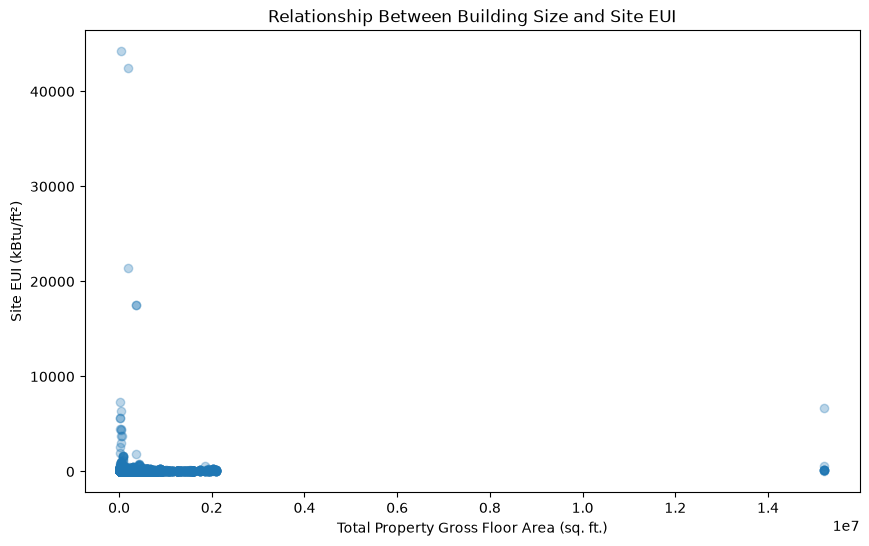

In [17]:

# Select two numerical variables and remove missing values
relationship_data = df[
    ["propertygfatotal", "siteeui_kbtu_sf"]
].dropna()

# Calculate Pearson correlation
r = relationship_data["propertygfatotal"].corr(
    relationship_data["siteeui_kbtu_sf"]
)

n = len(relationship_data)

print("Pearson's r:", r)
print("Number of observations:", n)

# Scatterplot
plt.figure(figsize=(10, 6))

plt.scatter(
    relationship_data["propertygfatotal"],
    relationship_data["siteeui_kbtu_sf"],
    alpha=0.3
)

plt.xlabel("Total Property Gross Floor Area (sq. ft.)")
plt.ylabel("Site EUI (kBtu/ft²)")
plt.title("Relationship Between Building Size and Site EUI")

plt.show()


#### Pearson Correlation Results


| Analysis | r | n | Note |
|---|---:|---:|---|
| All valid observations | 0.03697 | 36,747 | Very weak positive correlation; almost no linear relationship. |
| Sensitivity: after investigating an influential point | To be calculated | To be calculated | Check whether the correlation changes after investigating the extreme observation. |



#### Interpretation

The Pearson correlation is 0.03697, which indicates a very weak positive relationship between building size and Site EUI. This means that larger buildings do not necessarily have higher Site EUI.

The scatterplot shows that most observations are concentrated near the bottom, while a few buildings have extremely high Site EUI or very large floor areas. These unusual observations make the graph difficult to read and may influence the correlation.

Building size alone does not explain Site EUI. Other factors, such as building type, equipment, operating hours, and energy efficiency, may also affect energy use per square foot.

Correlation does not mean causation.


#### Sensitivity Analysis — Investigate an Influential Point

In [18]:

# Identify the observation with the largest floor area
largest_building = relationship_data.loc[
    relationship_data["propertygfatotal"].idxmax()
]

print(largest_building)

# Original correlation
original_r = relationship_data["propertygfatotal"].corr(
    relationship_data["siteeui_kbtu_sf"]
)

# Correlation after temporarily excluding the largest floor area observation
sensitivity_data = relationship_data.drop(
    relationship_data["propertygfatotal"].idxmax()
)

sensitivity_r = sensitivity_data["propertygfatotal"].corr(
    sensitivity_data["siteeui_kbtu_sf"]
)

print("Original r:", original_r)
print("Sensitivity r:", sensitivity_r)
print("Original n:", len(relationship_data))
print("Sensitivity n:", len(sensitivity_data))


propertygfatotal    15216474.0
siteeui_kbtu_sf          170.8
Name: 3038, dtype: float64
Original r: 0.036967164013445596
Sensitivity r: 0.037841263844025724
Original n: 36747
Sensitivity n: 36746



| Analysis | r | n | Note |
|---|---:|---:|---|
| All valid observations | 0.03697 | 36,747 | Very weak positive correlation. |
| Sensitivity: after investigating an influential point | 0.03784 | 36,746 | Correlation changed only slightly after temporarily excluding the largest floor-area observation. |



After temporarily excluding the observation with the largest floor area, Pearson's r changed from 0.03697 to 0.03784. The change was very small, meaning this observation did not strongly influence the overall correlation.

The relationship between building size and Site EUI remains very weak and positive. The observation was retained in the original dataset because it was not confirmed to be an error. This sensitivity check only shows how the correlation changes when one observation is temporarily excluded.

### Part D – Simulation: Sampling Variability

#### Monte Carlo Simulation

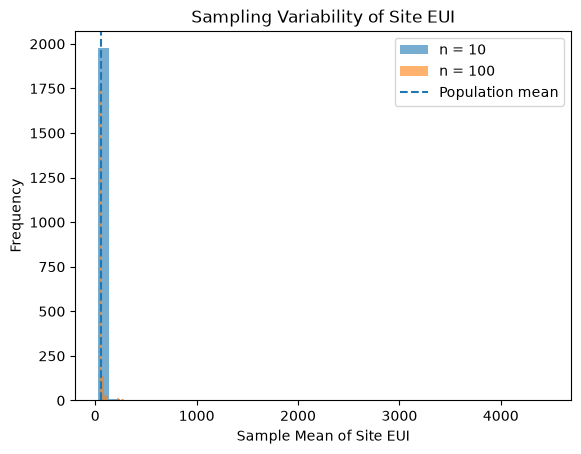

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Fixed seed for reproducibility
rng = np.random.default_rng(seed=2026)

# Population: all valid Site EUI observations
population = df["siteeui_kbtu_sf"].dropna().to_numpy()

# Population mean
population_mean = population.mean()

# Function to generate repeated sample means
def sample_means(n, reps=2000):
    return np.array([
        rng.choice(population, size=n, replace=False).mean()
        for _ in range(reps)
    ])

# Run simulations for sample sizes 10 and 100
results = {}

for n in (10, 100):
    means = sample_means(n)
    results[n] = means

    plt.hist(means, bins=40, alpha=0.6, label=f"n = {n}")

# Population mean reference line
plt.axvline(
    population_mean,
    linestyle="--",
    label="Population mean"
)

plt.xlabel("Sample Mean of Site EUI")
plt.ylabel("Frequency")
plt.title("Sampling Variability of Site EUI")
plt.legend()
plt.show()


In [ ]:
# Create summary table
summary = []

for n, means in results.items():
    summary.append({
        "Sample size n": n,
        "Repetitions": len(means),
        "Mean of sample means": means.mean(),
        "SD of sample means": means.std(ddof=1),
        "Population mean": population_mean
    })

sampling_summary = pd.DataFrame(summary)

sampling_summary.round(2)

,Sample size n,Repetitions,Mean of sample means,SD of sample means,Population mean
0,10,2000,62.37,163.92,57.19
1,100,2000,57.57,40.96,57.19



| Sample size (n) | Repetitions | Mean of sample means | SD of sample means | Population mean |
| :--- | :--- | :--- | :--- | :--- |
| **10** | 2,000 | 62.37 | 163.92 | 57.19 |
| **100** | 2,000 | 57.57 | 40.96 | 57.19 |

##### Interpretation

| Sample size | Interpretation |
| :--- | :--- |
| **n = 10** | The mean of sample means is 62.37, close to the population mean of 57.19. However, sample means have high variability (SD = 163.92). |
| **n = 100** | The mean of sample means is 57.57, also close to the population mean. The variability is much smaller (SD = 40.96). |
| **Comparison** | Larger samples produce more stable sample means and less sampling variability. |



**Main finding:** Increasing sample size from 10 to 100 reduced the standard deviation of sample means from 163.92 to 40.96.

##### Extension: Compare SD of Sample Means with SD ÷ √n

| Sample size ($n$) | Population SD | $\text{SD} \div \sqrt{n}$ | Simulated SD of sample means |
| :--- | :--- | :--- | :--- |
| 10 | 377.35 | 119.34 | 163.92 |
| 100 | 377.35 | 37.74 | 40.96 |

The results show that the simulated SD of sample means is close to the theoretical value of SD divided by the square root of the sample size.

For n = 10, the theoretical value is 119.34, while the simulated value is 163.92. For n = 100, the theoretical value is 37.74, while the simulated value is 40.96.

The differences may be due to random variation in the simulation. Overall, the results support the idea that larger sample sizes reduce sampling variability.

### Findings Memo

#### Research Question

What can the statistical analysis tell us about Site EUI, unusual energy-use observations, the relationship between building size and Site EUI, and sampling variability in Seattle building energy data?

#### Finding Memo Table


| Section | Answer |
| :--- | :--- |
| **Question** | What can statistical analysis tell us about the distribution of Site EUI, unusual energy-use observations, the relationship between building size and Site EUI, and sampling variability in Seattle building energy data? |
| **Key evidence** | Site EUI has a strongly right-skewed distribution, with a mean of 57.19 and median of 36.60. The IQR method identified 2,980 potential outliers. Building size and Site EUI have a very weak positive correlation ($r = 0.03697$). After temporarily excluding the largest floor-area observation, $r$ changed to $0.03784$. Sample means for $n = 100$ had lower variability ($\text{SD} = 40.96$) than for $n = 10$ ($\text{SD} = 163.92$). |
| **Assumptions** | Valid Site EUI observations were treated as the population for the sampling simulation. Each row represents a building-year observation. Pearson correlation was used to measure the linear relationship between total floor area and Site EUI. |
| **Limitations** | The dataset contains extreme values that strongly affect the mean and standard deviation. IQR identifies potential outliers but does not prove errors. Correlation does not imply causation. The simulation does not prove that the dataset represents a wider population. Some unusual records still need further verification. |
| **Recommendation / next step** | Investigate unusual Site EUI records using building information and energy-use data before correcting or removing them. Analyze Site EUI by building type or year to understand differences in energy use. Consider additional variables that may help explain energy efficiency. |


### INTERPRETATION

**1. Which summary statistics best describe your variable, and why?**

The median (36.60) and IQR (29.10) best describe Site EUI because the data is strongly right-skewed and contains extreme values. The median and IQR are less affected by unusually high observations than the mean and standard deviation.

**2. What does a plot reveal that the table of statistics does not?**

The histogram shows that most Site EUI values are concentrated at the lower end, while a few observations have extremely high values. The box plot also shows the potential outliers and the strong right-skewed distribution.

**3. Could your outliers be valid observations? What additional evidence would help?**

Yes. Some outliers may be valid observations from buildings with unusually high energy consumption. Building records, energy-use reports, floor area, and previous-year values could help determine whether the observations are errors or legitimate values.

**4. What does your correlation tell you, and what does it not tell you?**

The correlation (r = 0.03697) indicates a very weak positive linear relationship between building size and Site EUI. It does not mean that larger buildings necessarily have higher Site EUI, and it does not prove that building size causes changes in energy use per square foot.

**5. How did sample size affect the distribution of sample means?**

Increasing the sample size from 10 to 100 reduced the standard deviation of sample means from 163.92 to 40.96. The sample means became more concentrated around the population mean of 57.19, showing lower sampling variability with larger samples.

**6. What assumptions and limitations should a decision-maker know before using your findings?**

The analysis treats valid Site EUI observations as the population for the sampling simulation. Each row represents a building-year observation, and some buildings appear in multiple years. Extreme values affect the mean and standard deviation, while correlation only measures a linear relationship. The simulation does not prove that the dataset represents a wider population. Unusual observations should be verified before making decisions.
